In [1]:
# Cell 1 — Cài thư viện (chạy nếu môi trường chưa có)
!pip -q install timm scikit-learn seaborn tqdm

In [2]:
# Cell 2 — Import và cấu hình
import os
import pickle
import random
import copy
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import timm

from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA_DIR = "/kaggle/input/datasets/hiu309/cifar100/cifar-100-python"
BATCH_SIZE = 32
EPOCHS = 30
VAL_RATIO = 0.10
PATIENCE = 4
NUM_WORKERS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


In [3]:
# Cell 3 — Dataset đọc CIFAR-100 dạng pickle
class CIFAR100PickleDataset(Dataset):
    def __init__(self, file_path, transform=None):
        self.transform = transform
        with open(file_path, "rb") as f:
            entry = pickle.load(f, encoding="latin1")
        self.data = entry["data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
        self.labels = np.asarray(entry["fine_labels"], dtype=np.int64)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = Image.fromarray(self.data[idx])
        label = int(self.labels[idx])
        if self.transform is not None:
            image = self.transform(image)
        return image, label

train_file = os.path.join(DATA_DIR, "train")
test_file = os.path.join(DATA_DIR, "test")
meta_file = os.path.join(DATA_DIR, "meta")

for path in [train_file, test_file, meta_file]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Không tìm thấy: {path}\n"
            "Hãy kiểm tra DATA_DIR và cấu trúc thư mục CIFAR-100 trên Kaggle."
        )

with open(meta_file, "rb") as f:
    meta = pickle.load(f, encoding="latin1")
classes = meta.get("fine_label_names", meta.get(b"fine_label_names"))
classes = [c.decode("utf-8") if isinstance(c, bytes) else c for c in classes]

print("Số lớp:", len(classes))
print("Một số lớp:", classes[:10])


Số lớp: 100
Một số lớp: ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle']


In [4]:
# Cell 4 — Transforms
# Augmentation thực hiện trên ảnh gốc 32x32, sau đó mới resize.
# Chuẩn hóa ImageNet phù hợp với trọng số pretrained ImageNet.
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Hai bản của tập train để validation không bị augmentation.
train_aug_dataset = CIFAR100PickleDataset(train_file, transform=train_transform)
train_eval_dataset = CIFAR100PickleDataset(train_file, transform=eval_transform)
test_dataset = CIFAR100PickleDataset(test_file, transform=eval_transform)

val_size = int(VAL_RATIO * len(train_aug_dataset))
train_size = len(train_aug_dataset) - val_size

generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(train_aug_dataset), generator=generator).tolist()
train_indices = indices[:train_size]
val_indices = indices[train_size:]

train_dataset = Subset(train_aug_dataset, train_indices)
val_dataset = Subset(train_eval_dataset, val_indices)

print(f"Train: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}")


Train: 45000 | Validation: 5000 | Test: 10000


In [5]:
# Cell 5 — DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)

print(f"Batches — Train: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")


Batches — Train: 1407 | Val: 157 | Test: 313


In [6]:
# Cell 6 — Khởi tạo EfficientNetV2-B0 pretrained
def get_model():
    model = timm.create_model(
        "tf_efficientnetv2_b0.in1k",
        pretrained=True,
        num_classes=100,
        drop_rate=0.3
    )
    return model.to(DEVICE)

model = get_model()
print("Đã khởi tạo EfficientNetV2-B0.")


model.safetensors: reconstructing file:   0%|          |  0.00B / 28.8MB            

model.safetensors: downloading bytes:           |  0.00B            

Đã khởi tạo EfficientNetV2-B0.


In [7]:
# Cell 7 — Loss, optimizer và scheduler
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = optim.AdamW(
    model.parameters(),
    lr=2e-5,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.2,
    patience=2,
    min_lr=1e-7
)

print("Đã thiết lập CrossEntropy + label smoothing, AdamW và scheduler.")


Đã thiết lập CrossEntropy + label smoothing, AdamW và scheduler.


In [8]:
# Cell 8 — Hàm đánh giá
def evaluate_model(model, loader, criterion=None, verbose=True):
    model.eval()
    total_loss = 0.0
    total = 0
    correct = 0
    all_labels, all_preds, all_probs = [], [], []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Evaluating", leave=False):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)
            batch_size = labels.size(0)

            if criterion is not None:
                total_loss += criterion(outputs, labels).item() * batch_size

            predictions = outputs.argmax(dim=1)
            probabilities = torch.softmax(outputs, dim=1)

            total += batch_size
            correct += (predictions == labels).sum().item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(predictions.cpu().numpy())
            all_probs.extend(probabilities.cpu().numpy())

    results = {
        "loss": total_loss / total if criterion is not None and total else None,
        "accuracy": correct / total if total else 0.0,
        "y_true": np.asarray(all_labels),
        "y_pred": np.asarray(all_preds),
        "y_prob": np.asarray(all_probs),
    }

    if verbose:
        print(f"Accuracy: {results['accuracy'] * 100:.2f}%")
        if results["loss"] is not None:
            print(f"Loss: {results['loss']:.4f}")
    return results


In [9]:
# Cell 9 — Train loop có Early Stopping và checkpoint theo val_loss
def train_model(model, train_loader, val_loader, criterion, optimizer,
                scheduler, epochs=30, patience=4, checkpoint_path="efficientnetv2_b0_cifar100_best.pth"):
    history = {
        "train_loss": [], "train_accuracy": [],
        "val_loss": [], "val_accuracy": []
    }

    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    best_state = None

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total = 0
        correct = 0

        loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
        for images, labels in loop:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total += batch_size
            correct += (outputs.argmax(dim=1) == labels).sum().item()

            loop.set_postfix(
                loss=f"{total_loss / max(total, 1):.4f}",
                acc=f"{100 * correct / max(total, 1):.2f}%"
            )

        train_loss = total_loss / total
        train_acc = correct / total

        val_results = evaluate_model(
            model, val_loader, criterion=criterion, verbose=False
        )
        val_loss = val_results["loss"]
        val_acc = val_results["accuracy"]

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        scheduler.step(val_loss)
        current_lr = optimizer.param_groups[0]["lr"]

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss={train_loss:.4f}, Train Acc={train_acc*100:.2f}% | "
            f"Val Loss={val_loss:.4f}, Val Acc={val_acc*100:.2f}% | "
            f"LR={current_lr:.2e}"
        )

        # Chỉ lưu checkpoint khi validation loss cải thiện.
        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save(best_state, checkpoint_path)
            epochs_without_improvement = 0
            print(f"  -> Lưu checkpoint tốt nhất (epoch {best_epoch}, val_loss={best_val_loss:.4f})")
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"Early stopping: validation loss không cải thiện trong {patience} epoch.")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    print(f"Epoch tốt nhất: {best_epoch} | Best Val Loss: {best_val_loss:.4f}")
    return history


In [10]:
# Cell 10 — Huấn luyện
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=EPOCHS,
    patience=PATIENCE,
    checkpoint_path="efficientnetv2_b0_cifar100_best.pth"
)


Epoch 1/30:   0%|          | 0/1407 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 1/30 | Train Loss=4.0683, Train Acc=14.65% | Val Loss=2.9077, Val Acc=46.70% | LR=2.00e-05
  -> Lưu checkpoint tốt nhất (epoch 1, val_loss=2.9077)


Epoch 2/30:   0%|          | 0/1407 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

...

Epoch 23/30:   0%|          | 0/1407 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8fc5b02020>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8fc5b02020>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8fc5b02020>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8fc5b02020>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 23/30 | Train Loss=0.9932, Train Acc=94.79% | Val Loss=1.2747, Val Acc=85.08% | LR=8.00e-07
Early stopping: validation loss không cải thiện trong 4 epoch.
Epoch tốt nhất: 19 | Best Val Loss: 1.2679


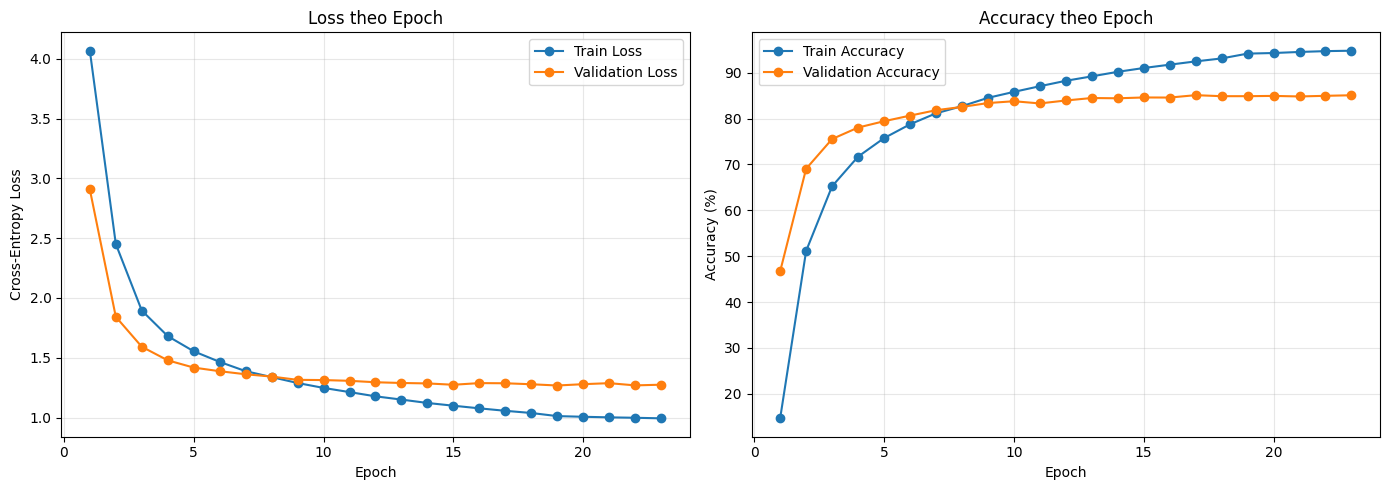

In [11]:
# Cell 11 — Vẽ biểu đồ Loss và Accuracy
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history["train_loss"], marker="o", label="Train Loss")
axes[0].plot(epochs_range, history["val_loss"], marker="o", label="Validation Loss")
axes[0].set_title("Loss theo Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(epochs_range, np.array(history["train_accuracy"]) * 100, marker="o", label="Train Accuracy")
axes[1].plot(epochs_range, np.array(history["val_accuracy"]) * 100, marker="o", label="Validation Accuracy")
axes[1].set_title("Accuracy theo Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


In [12]:
# Cell 12 — Nạp checkpoint tốt nhất và đánh giá test đúng một lần
model_test = get_model()
state = torch.load("efficientnetv2_b0_cifar100_best.pth", map_location=DEVICE)
model_test.load_state_dict(state)
model_test.eval()

print("=== KẾT QUẢ TRÊN TẬP TEST ===")
test_results = evaluate_model(model_test, test_loader, criterion=criterion)


=== KẾT QUẢ TRÊN TẬP TEST ===


Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

Accuracy: 84.49%
Loss: 1.2854


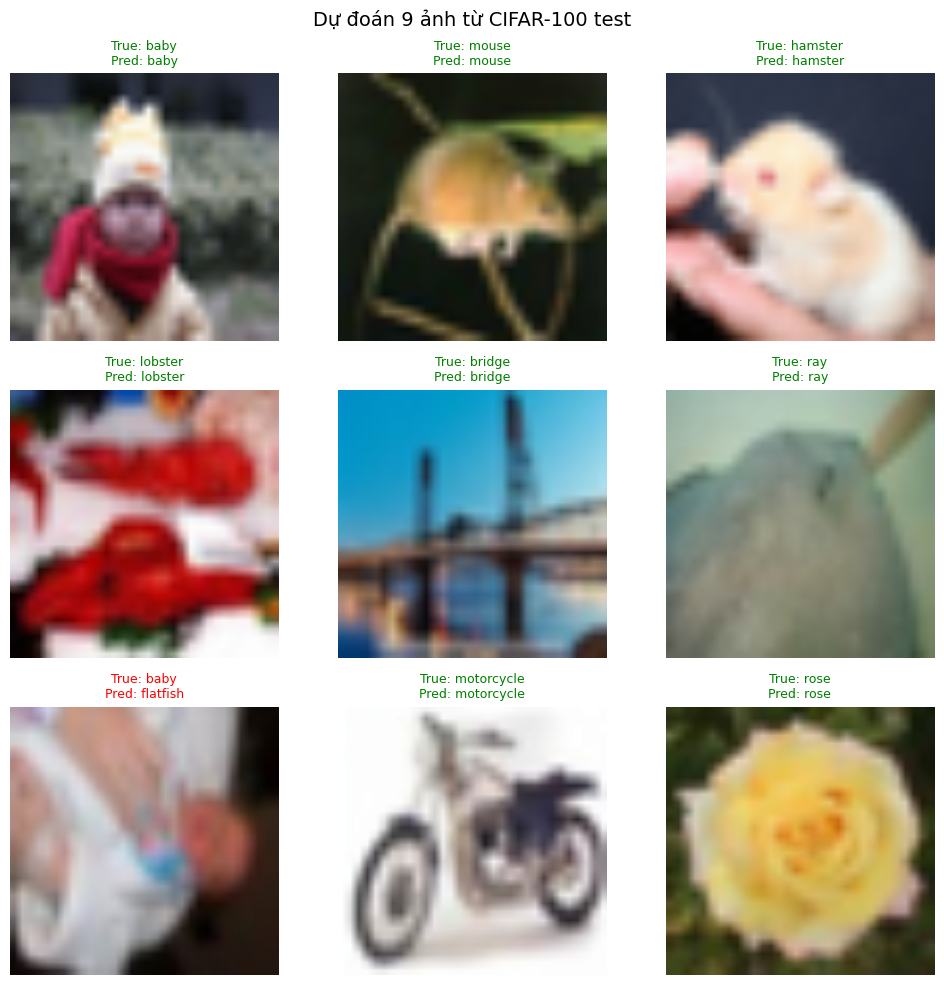

In [17]:
# Cell 13 — Hiển thị dự đoán 9 ảnh test
indices = random.sample(range(len(test_dataset)), 9)
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
axes = axes.flatten()

mean = np.array(IMAGENET_MEAN)
std = np.array(IMAGENET_STD)

model_test.eval()
for i, idx in enumerate(indices):
    image, label = test_dataset[idx]
    with torch.no_grad():
        output = model_test(image.unsqueeze(0).to(DEVICE))
        pred = output.argmax(dim=1).item()

    img = image.cpu().numpy().transpose(1, 2, 0)
    img = np.clip(img * std + mean, 0, 1)

    axes[i].imshow(img)
    axes[i].set_title(
        f"True: {classes[label]}\nPred: {classes[pred]}",
        color="green" if pred == label else "red",
        fontsize=9
    )
    axes[i].axis("off")

plt.suptitle("Dự đoán 9 ảnh từ CIFAR-100 test", fontsize=14)
plt.tight_layout()
plt.show()


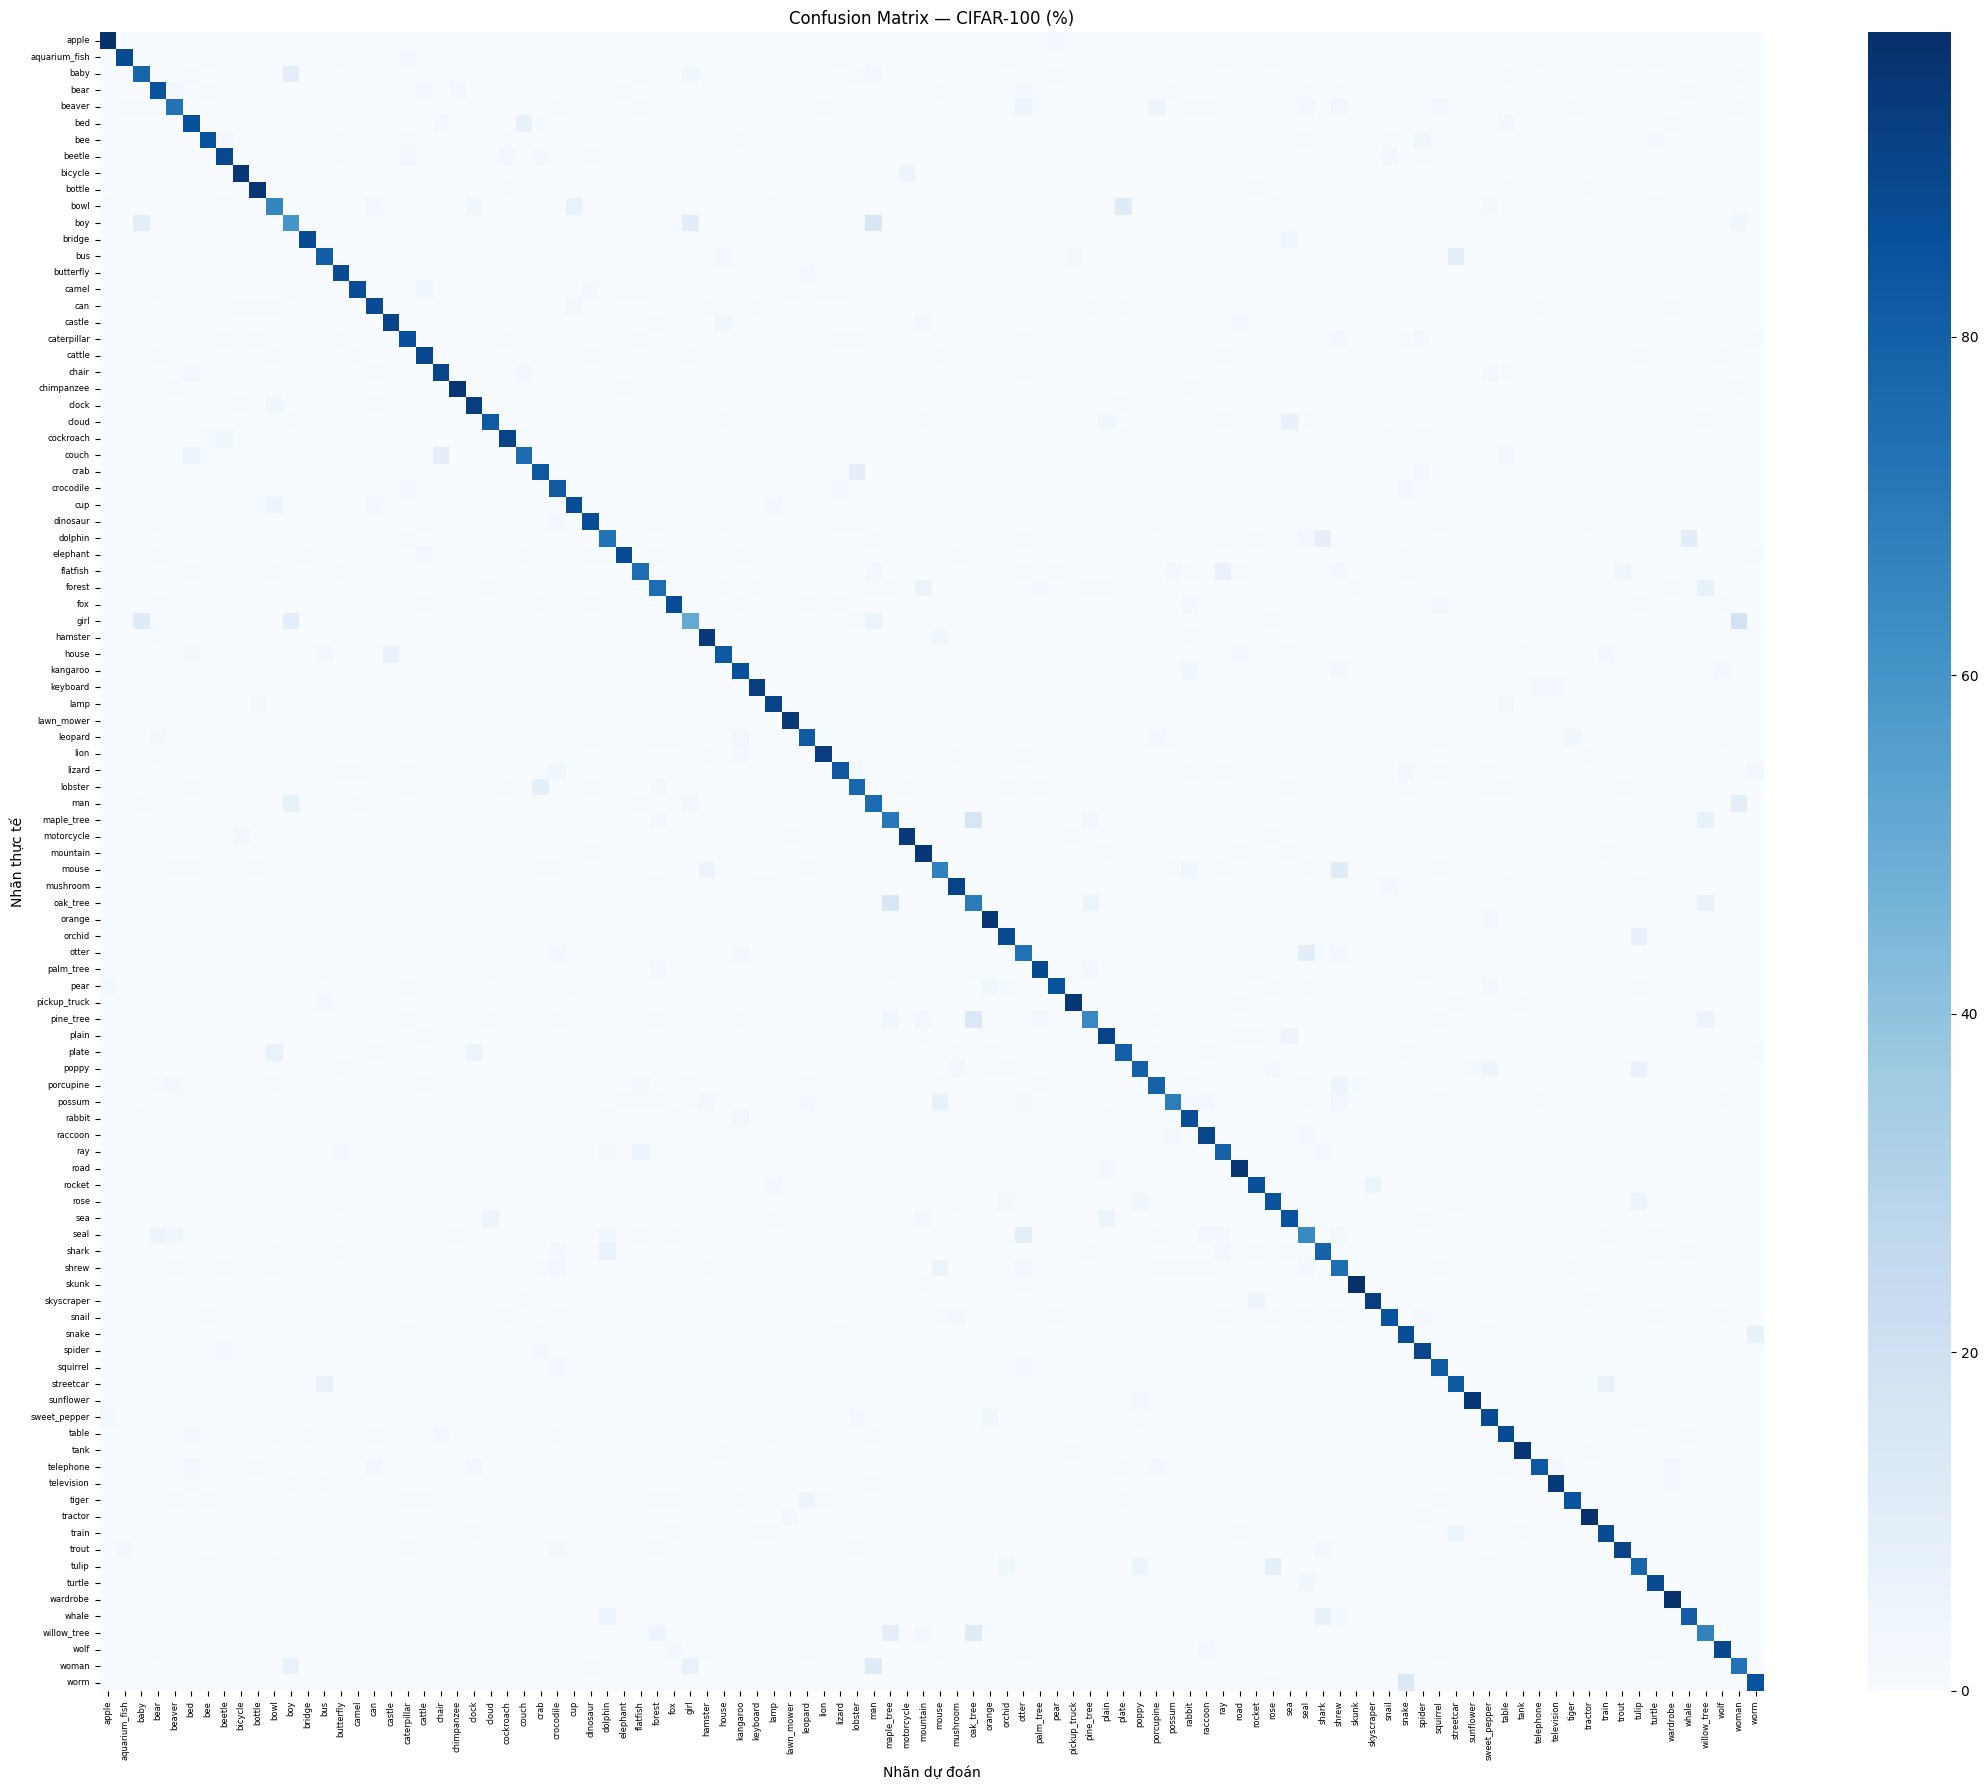

In [14]:
# Cell 14 — Confusion Matrix (chuẩn hóa theo phần trăm)
y_true = test_results["y_true"]
y_pred = test_results["y_pred"]

cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(classes)))
cm_normalized = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100

plt.figure(figsize=(22, 18))
sns.heatmap(
    cm_normalized,
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
    cbar=True
)
plt.title("Confusion Matrix — CIFAR-100 (%)")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.show()


In [15]:
# Cell 15 — Báo cáo precision/recall/F1 theo lớp (tùy chọn)
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    digits=3,
    zero_division=0
))


               precision    recall  f1-score   support

        apple      0.933     0.970     0.951       100
aquarium_fish      0.946     0.880     0.912       100
         baby      0.750     0.780     0.765       100
         bear      0.787     0.850     0.817       100
       beaver      0.820     0.730     0.772       100
          bed      0.819     0.860     0.839       100
          bee      0.914     0.850     0.881       100
       beetle      0.873     0.890     0.881       100
      bicycle      0.950     0.950     0.950       100
       bottle      0.923     0.960     0.941       100
         bowl      0.717     0.660     0.688       100
          boy      0.606     0.600     0.603       100
       bridge      0.936     0.880     0.907       100
          bus      0.862     0.810     0.835       100
    butterfly      0.880     0.880     0.880       100
        camel      0.946     0.870     0.906       100
          can      0.854     0.880     0.867       100
       ca